# B3. Histogram dan Perbaikan Citra (SIMUTEH, SEED 1014)

In [15]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak, statistik

## Langkah 3.1 Pemeriksaan lembar hitung manual dengan kode

In [16]:
M = np.array([[1,2,2,3],[2,2,3,3],[1,2,3,4],[2,3,3,2]])
L = 8
n = np.bincount(M.ravel(), minlength=L)
pdf = n / M.size; cdf = np.cumsum(pdf)
print("r :", list(range(L))); print("n :", n.tolist())
print("PDF:", pdf.round(4).tolist()); print("CDF:", cdf.round(4).tolist())
print("7xCDF:", (7*cdf).round(3).tolist()); s = np.round(7*cdf).astype(int)
print("s :", s.tolist()); print("hasil ekualisasi:\n", s[M])
rmin, rmax = M.min(), M.max()
print("hasil regang 0-7:\n", np.round((M - rmin) / (rmax - rmin) * 7).astype(int))
print("negatif 60 ->", 255 - 60)
for r in (120, 210): print(f"kontras 1.4r-30 untuk r={r}:", 1.4*r-30, "-> clip", int(np.clip(1.4*r-30, 0, 255)))
for g in (0.6, 1.8): print(f"gamma {g} untuk r=100:", round(255*(100/255)**g, 2))

r : [0, 1, 2, 3, 4, 5, 6, 7]
n : [0, 2, 7, 6, 1, 0, 0, 0]
PDF: [0.0, 0.125, 0.4375, 0.375, 0.0625, 0.0, 0.0, 0.0]
CDF: [0.0, 0.125, 0.5625, 0.9375, 1.0, 1.0, 1.0, 1.0]
7xCDF: [0.0, 0.875, 3.938, 6.562, 7.0, 7.0, 7.0, 7.0]
s : [0, 1, 4, 7, 7, 7, 7, 7]
hasil ekualisasi:
 [[1 4 4 7]
 [4 4 7 7]
 [1 4 7 7]
 [4 7 7 4]]
hasil regang 0-7:
 [[0 2 2 5]
 [2 2 5 5]
 [0 2 5 7]
 [2 5 5 2]]
negatif 60 -> 195
kontras 1.4r-30 untuk r=120: 138.0 -> clip 138
kontras 1.4r-30 untuk r=210: 264.0 -> clip 255
gamma 0.6 untuk r=100: 145.42
gamma 1.8 untuk r=100: 47.29


## Langkah 3.2 Diagnosis mutu (Tabel 9)

teh_041.png {'rerata': 170.1, 'simpangan_baku': 37.4, 'min': 61, 'maks': 232, 'persen_gelap': 0.0, 'persen_terang': 3.0}
teh_042.png {'rerata': 131.0, 'simpangan_baku': 41.6, 'min': 5, 'maks': 191, 'persen_gelap': 4.9, 'persen_terang': 0.0}
teh_043.png {'rerata': 210.8, 'simpangan_baku': 31.5, 'min': 136, 'maks': 253, 'persen_gelap': 0.0, 'persen_terang': 74.4}
teh_044.png {'rerata': 156.8, 'simpangan_baku': 14.8, 'min': 102, 'maks': 193, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 119.8, 'simpangan_baku': 49.0, 'min': 23, 'maks': 246, 'persen_gelap': 1.4, 'persen_terang': 5.5}
teh_021.png {'rerata': 175.1, 'simpangan_baku': 36.9, 'min': 80, 'maks': 225, 'persen_gelap': 0.0, 'persen_terang': 5.2}
teh_022.png {'rerata': 114.9, 'simpangan_baku': 42.3, 'min': 13, 'maks': 170, 'persen_gelap': 21.5, 'persen_terang': 0.0}
teh_023.png {'rerata': 213.0, 'simpangan_baku': 22.8, 'min': 140, 'maks': 250, 'persen_gelap': 0.0, 'persen_terang': 79.5}
teh_024.png {'rerata': 158.

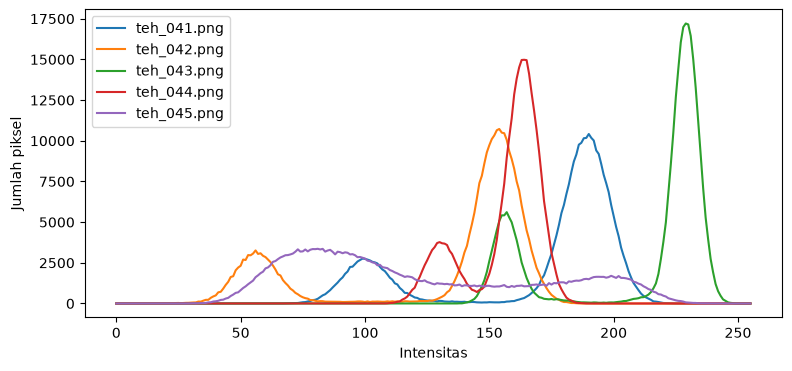

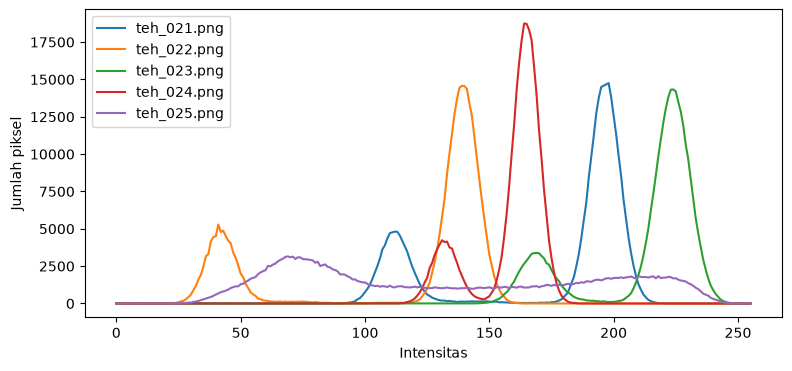

In [17]:
def gray_of(nm): return cv2.cvtColor(baca(f"../data/sintetis/citra/{nm}"), cv2.COLOR_BGR2GRAY)
plt.figure(figsize=(9, 4))
rows = []
for nama in ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]:
    gray = gray_of(nama)
    st = statistik(gray); print(nama, st)
    rows.append([nama] + list(st.values()))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png", dpi=100)
# lima citra kelas ringan teh_021-025 (kondisi sama dengan lima di atas)
hist_r = plt.figure(figsize=(9, 4))
for nama in ["teh_021.png", "teh_022.png", "teh_023.png", "teh_024.png", "teh_025.png"]:
    gray = gray_of(nama)
    st = statistik(gray); print(nama, st)
    rows.append([nama] + list(st.values()))
    plt.plot(cv2.calcHist([gray], [0], None, [256], [0, 256]), label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("../hasil/b3_histogram_ringan.png", dpi=100)
pd.DataFrame(rows, columns=["citra"] + list(statistik(gray).keys())).to_csv("../hasil/b3_tabel9.csv", index=False)

## Langkah 3.3 Perbaikan citra kondisi bayangan (Tabel 10)

persentil 2 dan 98: 52.0 214.0
asli       KB=1.56 sigma=49.0 rerata=119.8
negatif    KB=1.56 sigma=49.0 rerata=135.2
cerah+50   KB=1.56 sigma=48.2 rerata=169.3
kontras    KB=1.56 sigma=70.5 rerata=138.0
regang     KB=1.57 sigma=76.6 rerata=106.2
gamma0.5   KB=1.39 sigma=35.4 rerata=170.6
gamma1.8   KB=1.83 sigma=52.3 rerata=72.8
ekualisasi KB=1.19 sigma=73.4 rerata=128.4
CLAHE      KB=2.01 sigma=43.3 rerata=124.2


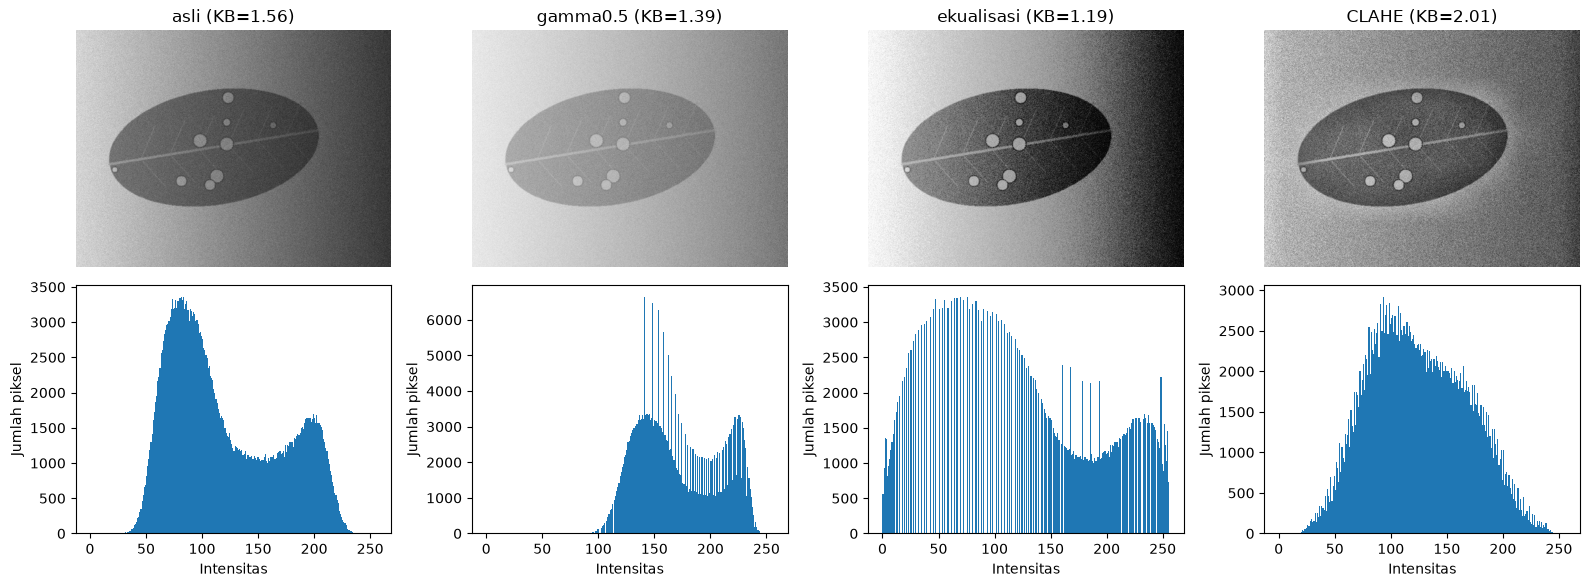

In [18]:
nama = "teh_045.png"  # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))  # abaikan 2% piksel ekstrem
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray.astype(float) - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray),
}
print("persentil 2 dan 98:", rmin, rmax)
rows = []
for nm, c in hasil.items():
    kb = kontras_bercak(c, md, mb)
    print(f"{nm:10s} KB={kb:.2f} sigma={c.std():.1f} rerata={c.mean():.1f}")
    rows.append([nm, round(kb, 2), round(float(c.std()), 1), round(float(c.mean()), 1)])
pd.DataFrame(rows, columns=["metode", "KB", "sigma", "rerata"]).to_csv("../hasil/b3_tabel10.csv", index=False)
# tata letak seperti Gambar 4: citra dan histogram
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for i, nm in enumerate(["asli", "gamma0.5", "ekualisasi", "CLAHE"]):
    ax[0, i].imshow(hasil[nm], cmap="gray", vmin=0, vmax=255); ax[0, i].set_title(f"{nm} (KB={kontras_bercak(hasil[nm], md, mb):.2f})"); ax[0, i].axis("off")
    ax[1, i].hist(hasil[nm].ravel(), bins=256, range=(0, 256)); ax[1, i].set_xlabel("Intensitas"); ax[1, i].set_ylabel("Jumlah piksel")
plt.tight_layout(); plt.savefig("../hasil/b3_perbandingan_bayangan.png", dpi=100)

## Langkah 3.4 Parameter CLAHE dan citra warna

clip=1.0 tile=4: KB=2.44
clip=1.0 tile=8: KB=2.11
clip=1.0 tile=16: KB=1.85
clip=2.0 tile=4: KB=2.45
clip=2.0 tile=8: KB=2.01
clip=2.0 tile=16: KB=1.77
clip=4.0 tile=4: KB=2.15
clip=4.0 tile=8: KB=1.68
clip=4.0 tile=16: KB=1.47
asli     Hue daun=57.2 Sat daun=180.9 rasio G/R=2.54 KB(R)=5.15 KB(H)=4.24
via V    Hue daun=57.2 Sat daun=182.2 rasio G/R=2.62 KB(R)=6.33 KB(H)=4.26
via BGR  Hue daun=64.7 Sat daun=140.4 rasio G/R=1.60 KB(R)=3.36 KB(H)=0.35


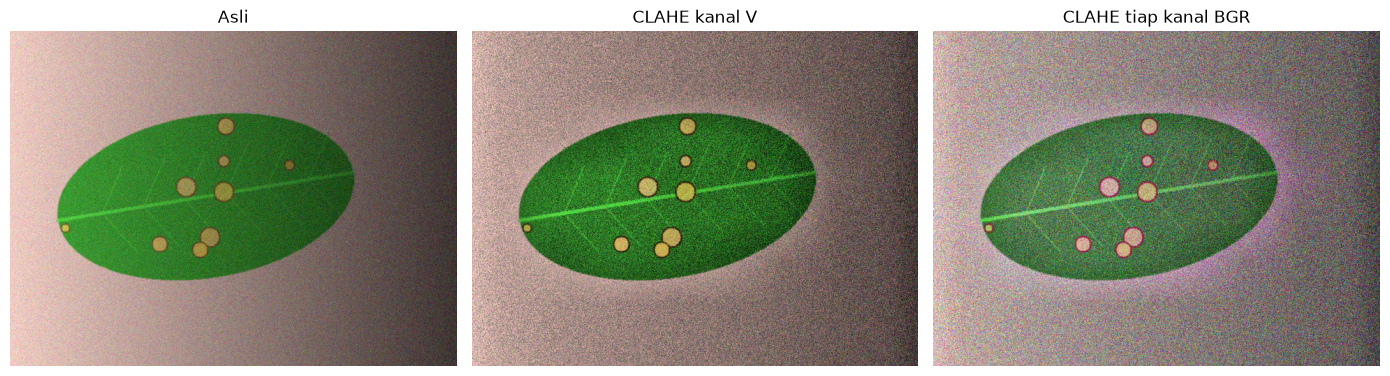

In [19]:
rows = []
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        kb = kontras_bercak(c, md, mb)
        print(f"clip={clip} tile={tile}: KB={kb:.2f}")
        rows.append([clip, tile, round(kb, 2), round(float(c.std()), 1)])
pd.DataFrame(rows, columns=["clip", "tile", "KB", "sigma"]).to_csv("../hasil/b3_clahe_param.csv", index=False)

# CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])
plt.savefig("../hasil/b3_clahe_warna.png", dpi=100)
# bukti kuantitatif pergeseran warna (hue di dalam daun sehat)
sehat = (md > 0) & (mb == 0)
def stat_warna(im):
    hh = cv2.cvtColor(im, cv2.COLOR_BGR2HSV)
    return hh[:, :, 0][sehat].mean(), hh[:, :, 1][sehat].mean(), im[:, :, 1][sehat].mean() / (im[:, :, 2][sehat].mean() + 1e-6)
for nm, im in [("asli", img), ("via V", via_v), ("via BGR", via_bgr)]:
    H_, S_, GR = stat_warna(im)
    print(f"{nm:8s} Hue daun={H_:.1f} Sat daun={S_:.1f} rasio G/R={GR:.2f} KB(R)={kontras_bercak(im[:, :, 2], md, mb):.2f} KB(H)={kontras_bercak(cv2.cvtColor(im, cv2.COLOR_BGR2HSV)[:, :, 0], md, mb):.2f}")

## Langkah 3.5 Satu perbaikan untuk setiap kondisi (kelas berat dan ringan)

                asli  gamma0.5  gamma1.5  gamma1.8  regang  CLAHE_2_8  CLAHE_2_4  ekualisasi
kondisi                                                                                     
bayangan        1.46      1.28      1.66      1.79    1.51       1.73       1.90        1.12
gelap           3.50      2.79      4.32      4.85    3.86       1.90       1.78        0.75
kontras_rendah  1.73      1.66      1.81      1.83    1.86       1.52       1.66        2.10
normal          3.55      3.19      3.93      4.25    3.85       1.89       2.01        1.08
terang          3.46      3.26      3.67      3.79    3.64       2.04       2.18        1.77
gelap           teh_042.png regang persentil 2-98  KB 2.81 -> 3.14
gelap           teh_022.png regang persentil 2-98  KB 4.28 -> 4.60
terang          teh_043.png gamma 1.8              KB 5.71 -> 6.30
terang          teh_023.png gamma 1.8              KB 2.52 -> 2.75
kontras_rendah  teh_044.png regang persentil 2-98  KB 2.36 -> 2.53
kontras_rendah

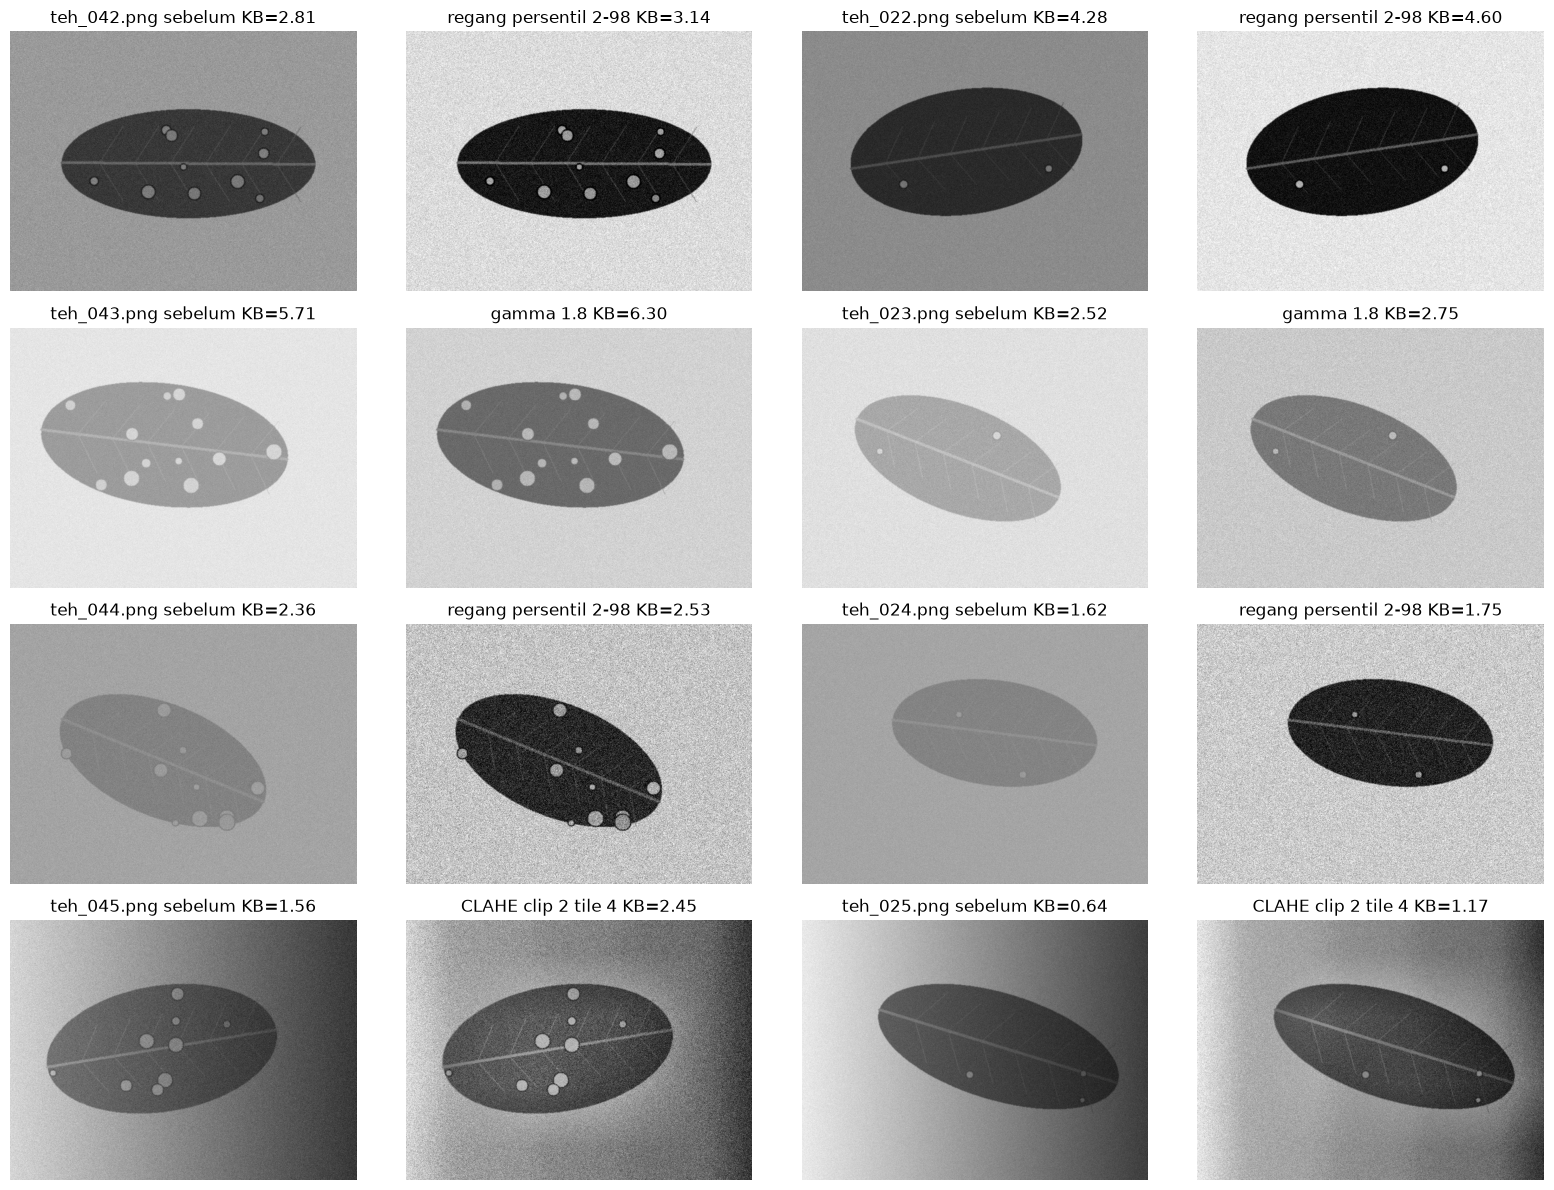

In [20]:
clahe8 = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
def regang(g):
    a, b = np.percentile(g, (2, 98)); return np.clip((g.astype(float) - a) / (b - a) * 255, 0, 255).astype(np.uint8)
# pilihan ditentukan dari tabel kandidat (rerata KB 8 citra bercak per kondisi), bukan dari selera visual
kandidat = {"asli": lambda g: g, "gamma0.5": lambda g: cv2.LUT(g, gamma_lut(0.5)),
            "gamma1.5": lambda g: cv2.LUT(g, gamma_lut(1.5)), "gamma1.8": lambda g: cv2.LUT(g, gamma_lut(1.8)),
            "regang": regang, "CLAHE_2_8": lambda g: clahe8.apply(g),
            "CLAHE_2_4": lambda g: cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4)).apply(g),
            "ekualisasi": cv2.equalizeHist}
lab = pd.read_csv("../data/sintetis/label.csv"); lab = lab[lab.kelas != "sehat"]
rk = []
for _, d in lab.iterrows():
    g = gray_of(d.nama_file)
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0); m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    r = {"kondisi": d.kondisi_cahaya}
    for k, f in kandidat.items(): r[k] = kontras_bercak(f(g), m_d, m_b)
    rk.append(r)
tk = pd.DataFrame(rk).groupby("kondisi").mean().round(2)
print(tk.to_string()); tk.to_csv("../hasil/b3_kandidat_perbaikan.csv")
perbaikan = {"gelap": ("regang persentil 2-98", regang),
             "terang": ("gamma 1.8", lambda g: cv2.LUT(g, gamma_lut(1.8))),
             "kontras_rendah": ("regang persentil 2-98", regang),
             "bayangan": ("CLAHE clip 2 tile 4", kandidat["CLAHE_2_4"])}
pasangan = {"gelap": ("teh_042.png", "teh_022.png"), "terang": ("teh_043.png", "teh_023.png"),
            "kontras_rendah": ("teh_044.png", "teh_024.png"), "bayangan": ("teh_045.png", "teh_025.png")}
fig, ax = plt.subplots(4, 4, figsize=(16, 12)); rows = []
for i, (kond, (nb, nr)) in enumerate(pasangan.items()):
    nmP, f = perbaikan[kond]
    for j, nm in enumerate([nb, nr]):
        g = gray_of(nm)
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0); m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
        out = f(g); k0, k1 = kontras_bercak(g, m_d, m_b), kontras_bercak(out, m_d, m_b)
        print(f"{kond:15s} {nm} {nmP:22s} KB {k0:.2f} -> {k1:.2f}")
        rows.append([kond, nm, nmP, round(k0, 2), round(k1, 2)])
        ax[i, 2*j].imshow(g, cmap="gray", vmin=0, vmax=255); ax[i, 2*j].set_title(f"{nm} sebelum KB={k0:.2f}")
        ax[i, 2*j+1].imshow(out, cmap="gray", vmin=0, vmax=255); ax[i, 2*j+1].set_title(f"{nmP} KB={k1:.2f}")
        ax[i, 2*j].axis("off"); ax[i, 2*j+1].axis("off")
plt.tight_layout(); plt.savefig("../hasil/b3_sebelum_sesudah.png", dpi=90)
pd.DataFrame(rows, columns=["kondisi", "citra", "perbaikan", "KB_sebelum", "KB_sesudah"]).to_csv("../hasil/b3_langkah35.csv", index=False)

## Tambahan untuk P3.5: gamma otomatis dari rerata intensitas (seluruh 40 citra bercak)

In [21]:
label = pd.read_csv("../data/sintetis/label.csv")
def gamma_auto(g, target=110.0):
    m = np.clip(g.mean(), 5, 250)
    return float(np.clip(np.log(target / 255) / np.log(m / 255), 0.4, 2.2))
rows = []
for _, d in label[label.kelas != "sehat"].iterrows():
    g = gray_of(d.nama_file)
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0); m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
    ga = gamma_auto(g)
    rows.append([d.kondisi_cahaya, g.mean(), ga, kontras_bercak(g, m_d, m_b),
                 kontras_bercak(cv2.LUT(g, gamma_lut(1.0)), m_d, m_b),
                 kontras_bercak(cv2.LUT(g, gamma_lut(0.5)), m_d, m_b),
                 kontras_bercak(cv2.LUT(g, gamma_lut(ga)), m_d, m_b)])
t = pd.DataFrame(rows, columns=["kondisi", "rerata", "gamma_auto", "KB_asli", "KB_g1", "KB_g0.5_tetap", "KB_auto"]).groupby("kondisi").mean().round(2)
print(t); t.to_csv("../hasil/b3_gamma_otomatis.csv")

                rerata  gamma_auto  KB_asli  KB_g1  KB_g0.5_tetap  KB_auto
kondisi                                                                   
bayangan        123.97        1.17     1.46   1.46           1.28     1.53
gelap           122.74        1.15     3.50   3.50           2.79     3.75
kontras_rendah  155.75        1.71     1.73   1.73           1.66     1.83
normal          172.41        2.11     3.55   3.55           3.19     4.51
terang          210.01        2.20     3.46   3.46           3.26     3.98
